In [1]:
# Rucno importovanje ssp modula:
import sys
sys.path.insert(0, '/home/emir/Faks/SIS2/Knjiga_SIS2/Prilozi/SIS2_Kodovi/')
import ssp

# Importovanje ostalih biblioteka:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.pyplot import hist

# Podesavanje prikaza za knjigu:
ssp.FORMATIRANJE_PRIKAZA = "BOOK"
ssp.REZOLUCIJA = "LOW"

# Podesavanje prikaza za rad studenata:
# ssp.FORMATIRANJE_PRIKAZA = "JUPYTER"
# ssp.REZOLUCIJA = "LOW"

In [2]:
#Programski kod 3.1

Očekivana vrijednost kod bacanja kockice za igru iznosi:  3.535


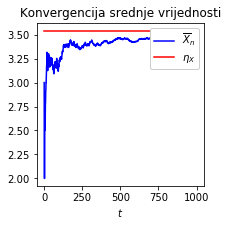

In [3]:
N = 1000
sr_vrijednost=[]
bacanja_kockice=[]
broj_bacanja = np.arange(0,N)
suma = 0.0

for n in broj_bacanja: 
    bacanja_kockice.append(np.random.choice(np.arange(1,7)))                                    
    suma = suma + bacanja_kockice[n]    
    sr_vrijednost.append(suma/(n+1))

ocekivana_vrijednost = np.mean(bacanja_kockice)

print("Očekivana vrijednost kod bacanja kockice za igru iznosi: ", 
      ocekivana_vrijednost)

ssp.slprom1D.grafik(broj_bacanja,sr_vrijednost, broj_bacanja, 
                    ocekivana_vrijednost*np.ones(len(broj_bacanja)),
                    naslov = "Konvergencija srednje vrijednosti",
                    legenda = ['$\overline{X}_n$','$\eta_X$'])

In [4]:
#Programski kod 3.2

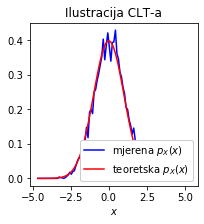

In [5]:
# Generiranje N = 5000 slučajnih promjenljivih 
# sa M = 500 uzoraka iz Rayleighove distribucije 

M = 500  #Broj uzoraka iz distribucije
N = 5000 #Broj slučajnih promjenljivih
eta = 3 

oc_vrijednost = np.sqrt(np.pi/2)*eta
sigma = np.sqrt(2-np.pi/2)*eta
X_n = np.empty([N,M])
X_n_norm = np.empty([N,M])

for n in range (N):
    X_n[n,:] = np.random.rayleigh(eta,M) 
    X_n_norm[n,:] = (X_n[n,:] - oc_vrijednost)/sigma
    
S_n = np.empty([N])
n_vektor = np.arange(0,N)

for n in n_vektor:
    S_n[n] = (1/np.sqrt(M))*np.sum(X_n_norm[n,:] ) 
    
x , p_Sn = ssp.slprom1D.pdf(S_n, prikaz = False)

def p_teoretsko(x):
    return (1/np.sqrt(2*np.pi))*np.exp(-(x**2)/2)

ssp.slprom1D.grafik(x, p_Sn, x, p_teoretsko(x),
                   naslov = "Ilustracija CLT-a", 
                   legenda = ['mjerena $p_X(x)$', 'teoretska $p_X(x)$'],
                   lokacija_lgd = 'lower right', x_labela = '$x$')